# Merger extraction results

Scores for every merger-extraction run saved under `outputs/`, with charts. Nothing is retrained or rescored here: the notebook only reads result files, so rerun it after any experiment to see the new scores.

**A run** is any folder under `outputs/` with a `per_field.csv` and a `summary.json`, written by `common.write_results`. The GLiNER scripts already do this:

```bash
.venv/bin/python mergers_extraction/gliner_finetuned_eval.py --name <model> --windows learned
.venv/bin/python mergers_extraction/gliner_zero_shot_eval.py --split holdout
```

A new method (Qwen, temporal NER, rules) shows up here once it writes its scores the same way; put `"method": "<name>"` in its `summary.json` to label it.

All scores are agreement with the LLM-extracted ground truth, which has not been checked by a person. See `FINETUNING.md` for the method.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

HERE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results.py").exists() or (p / "mergers_extraction" / "results.py").exists())
HERE = HERE if (HERE / "results.py").exists() else HERE / "mergers_extraction"
sys.path.insert(0, str(HERE))
import results  # noqa: E402

%matplotlib inline
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

## 1. All scored runs

Newest first. `micro_f1` uses the windows named in `windows` (`pipeline` = the original keyword windows of `src/merger_gliner.py`, `learned` = `window_selection.py`); `micro_f1_gt_passages` is the same model reading only the passages the ground truth quotes. Compare runs only when `split`, `filings` and `records` match: they were scored on the same held-out filings.

In [2]:
runs = results.discover_runs()
runs.drop(columns=["path"]).round(3)

,run,method,model,windows,split,filings,records,micro_f1,micro_precision,micro_recall,micro_f1_gt_passages,fields_scored,modified
0,pipeline/combined_medium_val_onepass_holdout,combined pipeline,medium_val_onepass,combined,holdout,103,179,0.469,0.424,0.525,NaN,19,2026-11-12 12:40:00
1,methods/cash_filter_medium_val_onepass_holdout,fine-tuned GLiNER + cash filter,medium_val_onepass,learned,holdout,103,179,0.761,0.818,0.711,NaN,1,2026-11-12 12:40:00
2,methods/validation/gliner_dates_medium_val_onepass,fine-tuned GLiNER + date checks,medium_val_onepass,learned,validation,52,80,0.750,0.700,0.808,NaN,3,2026-11-12 12:40:00
3,methods/validation/gliner_roles_medium_val_onepass,fine-tuned GLiNER + role checks,medium_val_onepass,learned,validation,52,80,0.806,0.774,0.842,NaN,3,2026-11-12 12:40:00
4,methods/validation/role_rule_medium_val_onepass,merger-agreement role rule + GLiNER,medium_val_onepass,fulltext,validation,52,80,0.820,0.786,0.856,NaN,3,2026-11-12 12:40:00
5,methods/validation/ratio_rule_medium_val_onepass,fine-tuned GLiNER + no-stock and formula checks,medium_val_onepass,learned,validation,52,80,0.342,0.303,0.392,NaN,1,2026-11-12 12:40:00
6,methods/gliner_dates_medium_val_onepass_holdout,fine-tuned GLiNER + date checks,medium_val_onepass,learned,holdout,103,179,0.629,0.557,0.722,NaN,3,2026-11-12 12:40:00
7,methods/validation/cash_filter_medium_val_onepass,fine-tuned GLiNER + cash filter,medium_val_onepass,learned,validation,52,80,0.537,0.440,0.688,NaN,1,2026-11-12 12:40:00
8,methods/gliner_roles_medium_val_onepass_holdout,fine-tuned GLiNER + role checks,medium_val_onepass,learned,holdout,103,179,0.771,0.719,0.831,NaN,3,2026-11-12 12:40:00
9,methods/ratio_rule_medium_val_onepass_holdout,fine-tuned GLiNER + no-stock and formula checks,medium_val_onepass,learned,holdout,103,179,0.488,0.437,0.554,NaN,1,2026-11-12 12:40:00


## 2. Choose a run

By default the newest fine-tuned run with learned windows. To look at another, set `FOCUS_RUN` to its `run` value from the table above. The baseline is zero-shot GLiNER on the same held-out filings and windows, when it was scored.

In [3]:
FOCUS_RUN = None  # e.g. "gliner_finetuned_medium_500steps_573filings_holdout/learned_windows/finetuned"

focus = runs.set_index("run").loc[FOCUS_RUN].copy() if FOCUS_RUN else results.default_focus(runs)
if FOCUS_RUN:
    focus["run"] = FOCUS_RUN
baseline = results.baseline_for(runs, focus)
same_holdout = results.comparable(runs, focus)

print("Focus:   ", results.label(focus))
print("Baseline:", results.label(baseline) if baseline is not None else "none scored")
print(f"{len(same_holdout)} runs scored on the same held-out filings")

Focus:    fine-tuned GLiNER, learned windows (medium_val_onepass, 52 validation filings)
Baseline: none scored
9 runs scored on the same held-out filings


## 3. Overall micro-F1 on the same held-out filings

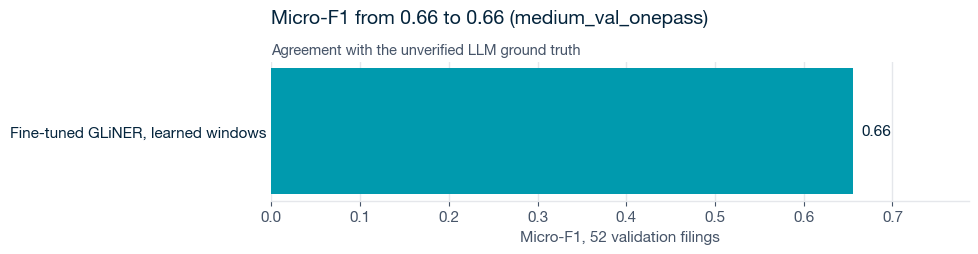

In [4]:
fig = results.overall_chart(same_holdout, focus)

## 4. F1 per field

Precision is how often an answer is right; recall is how many ground-truth values are found. `gt_absence_values` counts stated absences such as "No cash consideration", which a span model cannot produce and which are left out of F1. `quotes_in_windows` is how many of the field's ground-truth quotes fell inside the windows that were read.

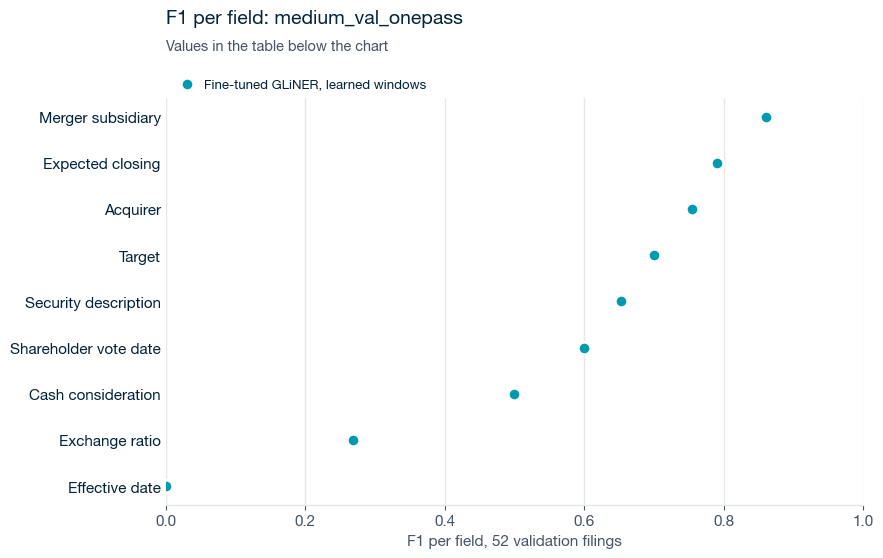

In [5]:
fig = results.per_field_chart(focus, baseline)

In [6]:
table = results.per_field(focus)
table["field"] = [results.FIELD_NAMES.get(f, f) for f in table.index]
table.set_index("field").round(2)

,tp,fp,fn,gt_absence_values,precision,recall,f1,gt_passages_f1,quotes_in_windows
field,,,,,,,,,
Acquirer,54,24,11,0,0.69,0.83,0.76,NaN,50/73
Target,56,24,24,0,0.70,0.70,0.70,NaN,61/80
Merger subsidiary,62,12,8,0,0.84,0.89,0.86,NaN,37/52
Security description,49,30,22,0,0.62,0.69,0.65,NaN,33/48
Cash consideration,12,20,4,5,0.38,0.75,0.50,NaN,10/14
Exchange ratio,17,59,34,13,0.22,0.33,0.27,NaN,23/59
Shareholder vote date,21,27,1,4,0.44,0.96,0.60,NaN,18/26
Effective date,0,7,2,0,0.00,0.00,0.00,NaN,2/2
Election deadline,0,0,2,0,NaN,0.00,NaN,NaN,0/1


## 5. Every run on these held-out filings, field by field

F1 per field (rows) and run (columns); darker is higher.

In [7]:
wide = results.field_table(same_holdout.sort_values("micro_f1", ascending=False))
wide.index = [results.FIELD_NAMES.get(f, f) for f in wide.index]
wide.style.format("{:.2f}", na_rep="—").background_gradient(cmap="Blues", vmin=0, vmax=1, axis=None)

,merger-agreement role rule + GLiNER | full filing text | medium_val_onepass | 52 filings,fine-tuned GLiNER + role checks | learned windows | medium_val_onepass | 52 filings,temporal NER + date rules | learned windows | temporal NER + date rules | 52 filings,fine-tuned GLiNER + date checks | learned windows | medium_val_onepass | 52 filings,date rules | full filing text | date rules | 52 filings,fine-tuned GLiNER | learned windows | medium_val_onepass | 52 filings,fine-tuned GLiNER + cash filter | learned windows | medium_val_onepass | 52 filings,fine-tuned GLiNER + no-stock and formula checks | learned windows | medium_val_onepass | 52 filings,Qwen3 4B | learned windows | Qwen3 4B | 52 filings
MICRO,0.82,0.81,0.76,0.75,0.70,0.66,0.54,0.34,0.28
Acquirer,0.69,0.66,—,—,—,0.76,—,—,—
available_options,—,—,—,—,—,—,—,—,0.00
Cash consideration,—,—,—,—,—,0.50,0.54,—,—
cash_consideration_qualifications,—,—,—,—,—,—,—,—,0.13
closing_conditions,—,—,—,—,—,—,—,—,0.03
consideration_type,—,—,—,—,—,—,—,—,0.16
default_option,—,—,—,—,—,—,—,—,0.00
Effective date,—,—,1.00,1.00,1.00,0.00,—,—,0.21
Election deadline,—,—,—,—,0.50,—,—,—,0.07


### Wrong answers and precision, field by field

For dates especially, a wrong answer is worse than no answer (a blank goes to a reviewer). `fp` counts wrong answers: a value where the ground truth has a different one or none. Precision is the share of answers that are right. Methods other than GLiNER answer only some fields, so their other cells are blank.

In [8]:
wrong = results.field_table(same_holdout.sort_values("micro_f1", ascending=False), metric="fp")
wrong.index = [results.FIELD_NAMES.get(f, f) for f in wrong.index]
wrong.style.format("{:.0f}", na_rep="—").background_gradient(cmap="Reds", axis=None)

,merger-agreement role rule + GLiNER | full filing text | medium_val_onepass | 52 filings,fine-tuned GLiNER + role checks | learned windows | medium_val_onepass | 52 filings,temporal NER + date rules | learned windows | temporal NER + date rules | 52 filings,fine-tuned GLiNER + date checks | learned windows | medium_val_onepass | 52 filings,date rules | full filing text | date rules | 52 filings,fine-tuned GLiNER | learned windows | medium_val_onepass | 52 filings,fine-tuned GLiNER + cash filter | learned windows | medium_val_onepass | 52 filings,fine-tuned GLiNER + no-stock and formula checks | learned windows | medium_val_onepass | 52 filings,Qwen3 4B | learned windows | Qwen3 4B | 52 filings
MICRO,50,53,17,9,9,221,14,46,544
Acquirer,30,32,—,—,—,24,—,—,—
available_options,—,—,—,—,—,—,—,—,31
Cash consideration,—,—,—,—,—,20,14,—,—
cash_consideration_qualifications,—,—,—,—,—,—,—,—,26
closing_conditions,—,—,—,—,—,—,—,—,74
consideration_type,—,—,—,—,—,—,—,—,68
default_option,—,—,—,—,—,—,—,—,80
Effective date,—,—,0,0,0,7,—,—,15
Election deadline,—,—,0,0,1,0,—,—,49


In [9]:
precision = results.field_table(same_holdout.sort_values("micro_f1", ascending=False), metric="precision")
precision.index = [results.FIELD_NAMES.get(f, f) for f in precision.index]
precision.style.format("{:.2f}", na_rep="—").background_gradient(cmap="Blues", vmin=0, vmax=1, axis=None)

,merger-agreement role rule + GLiNER | full filing text | medium_val_onepass | 52 filings,fine-tuned GLiNER + role checks | learned windows | medium_val_onepass | 52 filings,temporal NER + date rules | learned windows | temporal NER + date rules | 52 filings,fine-tuned GLiNER + date checks | learned windows | medium_val_onepass | 52 filings,date rules | full filing text | date rules | 52 filings,fine-tuned GLiNER | learned windows | medium_val_onepass | 52 filings,fine-tuned GLiNER + cash filter | learned windows | medium_val_onepass | 52 filings,fine-tuned GLiNER + no-stock and formula checks | learned windows | medium_val_onepass | 52 filings,Qwen3 4B | learned windows | Qwen3 4B | 52 filings
MICRO,0.79,0.77,0.78,0.70,0.68,0.59,0.44,0.30,0.23
Acquirer,0.62,0.60,—,—,—,0.69,—,—,—
available_options,—,—,—,—,—,—,—,—,0.00
Cash consideration,—,—,—,—,—,0.38,0.44,—,—
cash_consideration_qualifications,—,—,—,—,—,—,—,—,0.13
closing_conditions,—,—,—,—,—,—,—,—,0.03
consideration_type,—,—,—,—,—,—,—,—,0.15
default_option,—,—,—,—,—,—,—,—,0.00
Effective date,—,—,1.00,1.00,1.00,0.00,—,—,0.12
Election deadline,—,—,—,—,0.50,—,—,—,0.04


## 6. Which windows GLiNER reads

From `window_selection.py`: the share of held-out ground-truth values that fall inside the windows read, for the original keyword windows, the first N windows of the filing, and the learned selector.

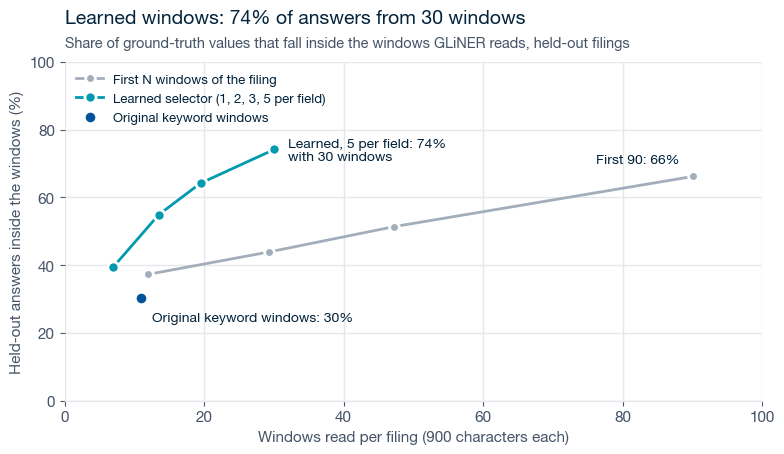

In [10]:
fig = results.window_budget_chart()

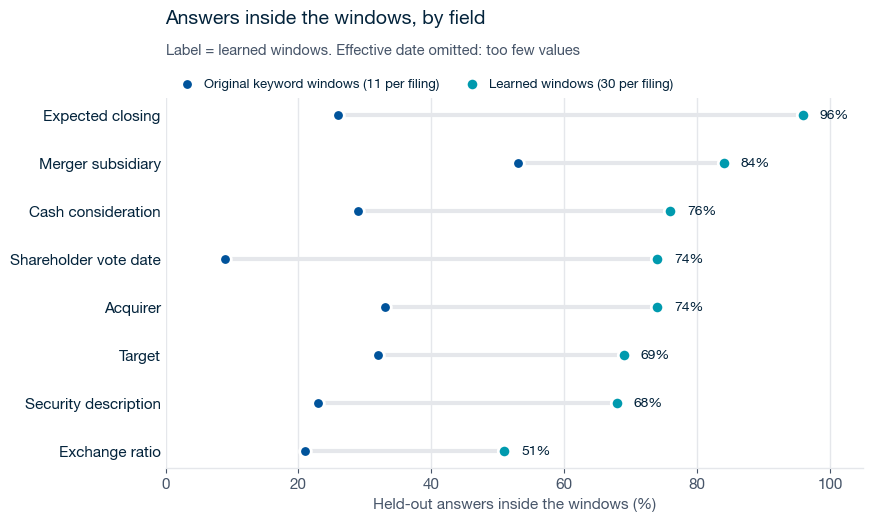

In [11]:
fig = results.window_fields_chart()

In [12]:
pd.read_csv(results.common.OUTPUTS / "window_selector" / "answer_recall.csv")

,strategy,avg_windows,overall,acquirer,target,merger_subsidiary,security_description,cash_consideration,stock_exchange_ratio,shareholder_vote_date,effective_date,expected_closing
0,original keyword windows (12),10.9,0.302,0.33,0.32,0.53,0.23,0.29,0.21,0.09,1.0,0.26
1,first 12 windows,12.0,0.373,0.53,0.50,0.58,0.29,0.21,0.23,0.11,0.0,0.11
2,first 30 windows,29.3,0.439,0.60,0.57,0.62,0.35,0.29,0.26,0.31,0.0,0.16
3,first 50 windows,47.3,0.514,0.68,0.66,0.73,0.40,0.35,0.28,0.34,1.0,0.24
4,first 100 windows,90.1,0.662,0.81,0.80,0.87,0.56,0.53,0.42,0.60,1.0,0.39
5,"learned, 1 per field (10)",7.0,0.395,0.39,0.42,0.36,0.32,0.35,0.33,0.31,1.0,0.66
6,"learned, 2 per field (20)",13.5,0.549,0.55,0.50,0.60,0.51,0.50,0.37,0.49,1.0,0.81
7,"learned, 3 per field (30)",19.5,0.642,0.65,0.57,0.67,0.60,0.68,0.42,0.66,1.0,0.91
8,"learned, 5 per field (50)",30.1,0.742,0.74,0.69,0.84,0.68,0.76,0.51,0.74,1.0,0.96


## 7. Training data and training

Share of ground-truth values found in the filing text (only those become training examples), and the training loss of the focus model.

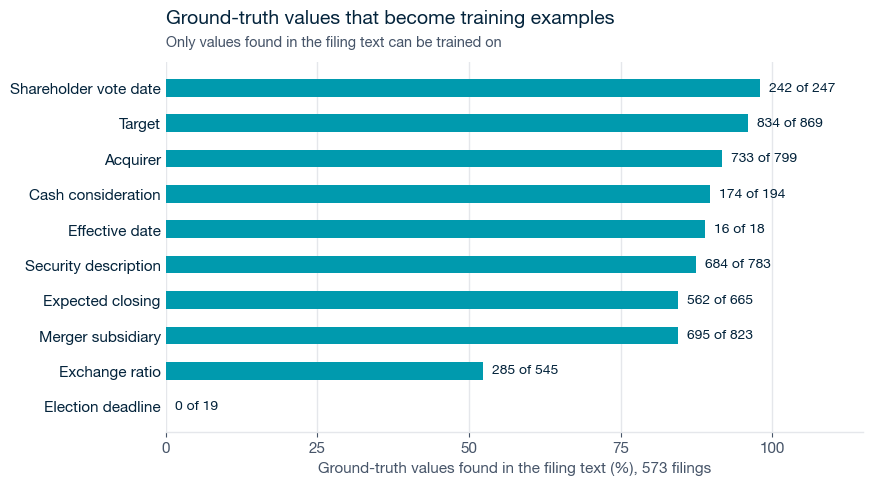

In [13]:
fig = results.training_data_chart()

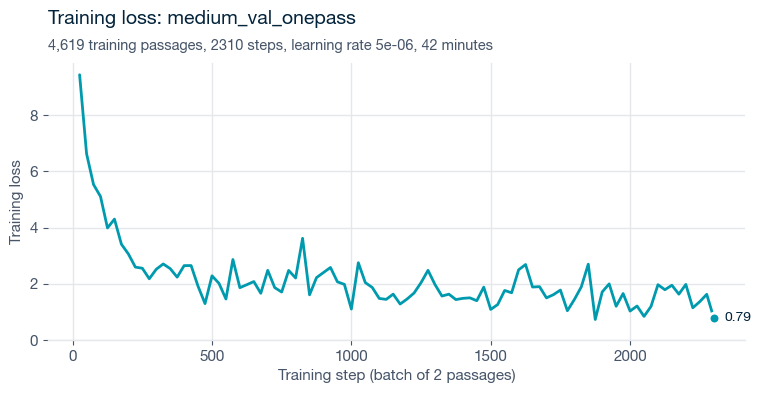

In [14]:
if focus["method"] == "fine-tuned GLiNER":
    fig = results.training_loss_chart(focus["model"])
else:
    print("The focus run is not a fine-tuned model")

## 8. Save the charts (optional)

Writes the charts above to `figures/` for documents and slides. `make_figures.py` does the same from the command line.

In [15]:
SAVE_FIGURES = False

if SAVE_FIGURES:
    import matplotlib.pyplot as plt
    figures = {
        "01_overall_micro_f1.png": results.overall_chart(same_holdout, focus),
        "02_per_field_f1.png": results.per_field_chart(focus, baseline),
        "03_window_coverage.png": results.window_budget_chart(),
        "04_window_coverage_by_field.png": results.window_fields_chart(),
        "05_training_values_located.png": results.training_data_chart(),
    }
    if focus["method"] == "fine-tuned GLiNER":
        figures["06_training_loss.png"] = results.training_loss_chart(focus["model"])
    for name, fig in figures.items():
        print("wrote", results.save(fig, name))
        plt.close(fig)